<!-- DOC-BANNER -->
# Feature Scaling — Standardization in practice (Day 24)

> **Playlist:** CampusX Day 24 *Feature Scaling - Standardization*.
> **Purpose:** Prove *why* scaling matters on `Social_Network_Ads.csv` (`Age/EstimatedSalary/Purchased` via `iloc[:,2:]`): `train_test_split(.2, rs=42)` → `StandardScaler` fit-on-train/transform-both → `mean_`/`describe` → scatter + `kdeplot` (Age+Salary, Age-only, Salary-only) → `LogisticRegression` scaled-vs-unscaled accuracy → `DecisionTree` scaled-vs-unscaled accuracy → inject synthetic outliers (`Age [5,90,95]`, Salary `[1000,250k,350k]`) → re-split/re-scale → show Standardization is NOT outlier-proof → *when-to-apply* + `image.png`.
> **After studying:** you can state the rule the notebook demonstrates: distance-based `LogReg` improves with scaling; tree splits do not care.


### Feature scaling is  the techinique to standorize the independent  features in the data in fixed range  

## Types  of the feature scaling 


## Standerisation and Normalisaation 

In [ ]:
import matplotlib.pyplot as plt 
import  seaborn as sns 
import pandas as pd 
import numpy as  np 



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="husl",
    font="sans-serif",
    font_scale=1.1,
    rc={
        "figure.figsize": (10, 6),
        "figure.dpi": 120,
        "axes.titlesize": 18,
        "axes.titleweight": "bold",
        "axes.labelsize": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.alpha": 0.25,
        "lines.linewidth": 2.5,
        "lines.markersize": 7,
        "legend.frameon": False,
        "figure.autolayout": True
    }
)

plt.rcParams["figure.facecolor"] = "#1e1e2f"
plt.rcParams["axes.facecolor"] = "#282840"
plt.rcParams["axes.labelcolor"] = "#eeeeff"
plt.rcParams["text.color"] = "#eeeeff"
plt.rcParams["xtick.color"] = "#ccccdd"
plt.rcParams["ytick.color"] = "#ccccdd"
plt.rcParams["grid.color"] = "#777799"

In [ ]:
df = pd.read_csv(r"E:\MACHINE_LEARNING\DATA_SETS\Social_Network_Ads.csv")
df = df.iloc[: , 2 : ]
df.sample(5)


Train-Test Split in Machine Learning

Before applying Feature Scaling, you should generally perform a Train-Test Split. Let's understand why, when to do it, and how to implement it in Python.

1. What is Train-Test Split?

Suppose you have a dataset containing 1,000 rows that you want to use to train a Machine Learning model.

You divide the dataset into two parts:

Training Set: Used to train the ML model.
Testing Set: Used to evaluate how well the model performs on unseen data.

For example, with an 80:20 split:

Dataset	Percentage	Number of Rows	Purpose
Training data	80%	800	Train the model
Testing data	20%	200	Evaluate the model
Total	100%	1,000	Original dataset

The model learns patterns from the 800 training rows. We then evaluate it using the 200 testing rows.

Why do we do this?

We want to determine whether our model has learned general patterns or has simply memorized the training data.

# FOR FEATURE SCALLING ALWAYS DO TRAN TEST SPLIT 


In [ ]:
from sklearn.model_selection import train_test_split as tts
x= df.drop(columns =['Purchased'])
y= df['Purchased']
X_train , X_test , Y_train , Y_test = tts(x,  y , test_size = .2 , random_state = 42  )

# NOW SCALING 

### 1. Correct fit/transform — `StandardScaler`, `train_test_split`
`fit` on `X_train` ONLY (learns mean/std), `transform` both splits. `ALWAYS DO TRAIN TEST SPLIT` first — fitting on full data leaks test info. Formula: `z = (x - mean) / std`.

In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler()

#  fitting of the Train set , it will leran the parameters
scaler = scaler.fit(X_train)


# transform the Trian and test 


X_train_scaled = scaler.transform( X_train )
X_test_scaled = scaler.transform(X_test)


In [ ]:
scaler.mean_

In [ ]:
X_train_scaled

In [ ]:
X_train_scaled = pd.DataFrame(X_train_scaled , columns= X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled , columns = X_test.columns)



In [ ]:
np.round(X_train_scaled.describe() , 1)

# EFFECT OF SCALING 


In [ ]:
fig , (ax1 , ax2 )= plt.subplots(ncols = 2  , figsize= (18 ,8))
ax1.scatter(X_train["Age"], X_train["EstimatedSalary"])
ax1.set_title("BEFORE SCALLING ")
ax2.scatter(X_train_scaled["Age"], X_train_scaled["EstimatedSalary"] , color= "red")
ax2.set_title("AFTER SCALLING ")



### 3. Seeing the effect — scatter + `kdeplot`
Before: Salary axis dwarfs Age. After: both ~N(0,1), scatter circular, KDEs centered at 0. Outlier demo re-stretches the axes — hence *Standardization != outlier-proof* (use RobustScaler then; see Day 25). Note: 3 KDE cells set `ax1.set_title` twice (`ax2` never titled); one outlier `ax2.scatter` is commented out; one `lr=` init cell is duplicated.

In [ ]:
fig , (ax1 , ax2 )= plt.subplots(ncols = 2  , figsize= (18 ,8))

ax1.set_title("BEFORE SCALLING ")
sns.kdeplot(X_train['Age'] , ax = ax1)
sns.kdeplot(X_train['EstimatedSalary'] ,ax = ax1)

ax2.set_title("AFTER SCALLING ")


ax1.set_title("BEFORE SCALLING ")
sns.kdeplot(X_train_scaled['Age'] ,  ax = ax2)
sns.kdeplot(X_train_scaled['EstimatedSalary'] ,ax = ax2)



# Comparison of Distributiobns 


In [ ]:
fig , (ax1 , ax2 )= plt.subplots(ncols = 2  , figsize= (18 ,8))

ax1.set_title("BEFORE SCALLING ")
sns.kdeplot(X_train['Age'] , ax = ax1)
# sns.kdeplot(X_train['EstimatedSalary'] ,ax = ax1)

ax2.set_title("AFTER SCALLING ")


ax1.set_title("BEFORE SCALLING ")
sns.kdeplot(X_train_scaled['Age'] ,  ax = ax2)
# sns.kdeplot(X_train_scaled['EstimatedSalary'] ,ax = ax2)



In [ ]:
fig , (ax1 , ax2 )= plt.subplots(ncols = 2  , figsize= (18 ,8))

ax1.set_title("BEFORE SCALLING ")
# sns.kdeplot(X_train['Age'] , ax = ax1)
sns.kdeplot(X_train['EstimatedSalary'] ,ax = ax1)

ax2.set_title("AFTER SCALLING ")


ax1.set_title("BEFORE SCALLING ")
# sns.kdeplot(X_train_scaled['Age'] ,  ax = ax2)
sns.kdeplot(X_train_scaled['EstimatedSalary'] ,ax = ax2)



# WHY SCALLING IS IIMPORTANT 

### 2. Who benefits — `LogisticRegression` vs `DecisionTreeClassifier`
`LogReg` (gradient/distance-based) trains better scaled; `DecisionTree` (threshold splits) gives ~same accuracy scaled or not. `accuracy_score` quantifies it (cells currently `null` — re-run to see numbers).

In [ ]:
from sklearn.linear_model  import  LogisticRegression

In [ ]:
lr = LogisticRegression()
lr_scaled = LogisticRegression()




In [ ]:
lr = LogisticRegression()
lr_scaled = LogisticRegression()

In [ ]:
lr.fit(X_train , Y_train)

lr_scaled.fit(X_train_scaled , Y_train)

In [ ]:
y_pred = lr.predict(X_test)
y_pred_scaled = lr_scaled.predict(X_test_scaled)

In [ ]:
from sklearn.metrics import accuracy_score 

In [ ]:
print("ACT ->" , accuracy_score( Y_test , y_pred))

print(" SCALED ->" , accuracy_score(Y_test , y_pred_scaled) )

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier()
dt_scaled =  DecisionTreeClassifier()


dt.fit(X_train, Y_train )

dt_scaled.fit(X_train_scaled , Y_train)





In [ ]:
y_pred = dt.predict(X_test)


y_pred_scaled = dt_scaled.predict(X_test_scaled)




In [ ]:
print("ACT ->" , accuracy_score( Y_test , y_pred))

print(" SCALED ->" , accuracy_score(Y_test , y_pred_scaled) )

# EFFECT OF OUTLIER 



In [ ]:
new_data = pd.DataFrame({
    'Age': [5, 90, 95],
    'EstimatedSalary': [1000, 250000, 350000],
    'Purchased': [0, 1, 1]
})

In [ ]:
df = pd.concat([df, new_data], ignore_index=True)

In [ ]:
fig , (ax1 , ax2 )= plt.subplots(ncols = 2  , figsize= (18 ,8))
ax1.scatter(df["Age"], df["EstimatedSalary"])
ax1.set_title("BEFORE SCALLING ")
# ax2.scatter(X_train_scaled["Age"], X_train_scaled["EstimatedSalary"] , color= "red")
ax2.set_title("AFTER SCALLING ")



# AGAIN TRAINING DATA


In [ ]:
from sklearn.model_selection import train_test_split as tts
x= df.drop(columns =['Purchased'])
y= df['Purchased']

X_train , X_test , Y_train , Y_test = tts(x,  y , test_size = .2 , random_state = 42  )


In [ ]:
from sklearn.preprocessing import StandardScaler

In [ ]:
scaler = StandardScaler()

#  fitting of the Train set , it will leran the parameters
scaler = scaler.fit(X_train)


# transform the Trian and test 


X_train_scaled = scaler.transform( X_train )
X_test_scaled = scaler.transform(X_test)


In [ ]:
scaler.mean_


In [ ]:
X_train_scaled = pd.DataFrame(X_train_scaled , columns= X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled , columns = X_test.columns)



# EFFECT OF SCALING 


In [ ]:
fig , (ax1 , ax2 )= plt.subplots(ncols = 2  , figsize= (18 ,8))
ax1.scatter(X_train["Age"], X_train["EstimatedSalary"])
ax1.set_title("BEFORE SCALLING ")
ax2.scatter(X_train_scaled["Age"], X_train_scaled["EstimatedSalary"] , color= "red")
ax2.set_title("AFTER SCALLING ")



In [ ]:
fig , (ax1 , ax2 )= plt.subplots(ncols = 2  , figsize= (18 ,5))

ax1.set_title("BEFORE SCALLING ")
sns.kdeplot(X_train['Age'] , ax = ax1)
sns.kdeplot(X_train['EstimatedSalary'] ,ax = ax1)

ax2.set_title("AFTER SCALLING ")


ax1.set_title("BEFORE SCALLING ")
sns.kdeplot(X_train_scaled['Age'] ,  ax = ax2)
sns.kdeplot(X_train_scaled['EstimatedSalary'] ,ax = ax2)



# STANDARIZATION DOES NOT REDUCE THE EFFECT OF THE OUTLIERS 

## YOU HAVE TO HADLE IT MANUALLY 



# WHEN TO APPLY STANDARIZATION
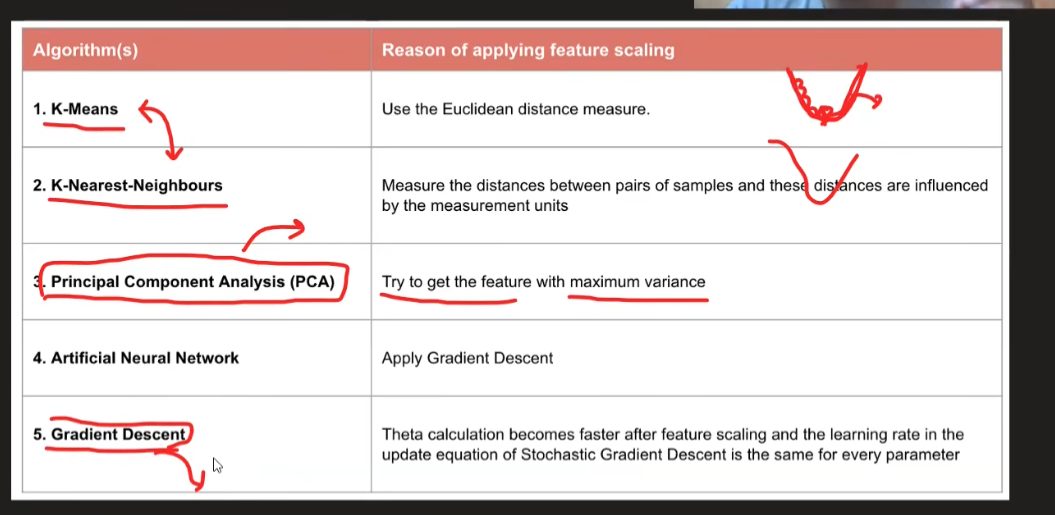



<!-- EXPERIMENT -->
### Experiment: move the split, move the result
Change `test_size=0.2` to `0.3` (keep `random_state=42`) and predict how the train/test shapes change. Then drop the 3 injected outlier rows and re-run the scaled-vs-unscaled LogisticRegression comparison — does the accuracy gap shrink? It should: fewer extremes, less distortion.

<!-- DOC-BANNER -->
## Key takeaways (Day 24)
- `fit_transform(train)`, `transform(test)` — never `fit` on test.
- Scale for distance/gradient models (`LogReg`, KNN, SVM, neural nets); optional for trees.
- Standardization centers but does not remove outliers.
- Typo `scaaling/standorize` preserved; see [Day-25 note](../Day_25/topic_notes.md) for Standardization vs Normalization (they are DIFFERENT — the stub notebook conflates them).
